<a href="https://colab.research.google.com/github/shafi21001/fruit-freshness-edge-ai-study/blob/main/notebooks/05_explainability_gradcam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ============================================================
# CELL 1 — ENVIRONMENT & FILE VERIFICATION
# CPU ONLY — No GPU required
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import importlib.util

# Project locations
PROJECT_ROOT = "/content/drive/MyDrive/Fruit_Freshness_Research"
EXPERIMENT_DIR = os.path.join(
    PROJECT_ROOT, "experiments", "baseline_mobilenetv3_small"
)
VALIDATION_DIR = os.path.join(EXPERIMENT_DIR, "validation_analysis")

CHECKPOINT_PATH = os.path.join(
    EXPERIMENT_DIR, "checkpoints", "best_validation_macro_f1.pt"
)

XAI_SELECTION_PATH = os.path.join(
    VALIDATION_DIR, "predefined_xai_selection_epoch11.csv"
)

PREDICTIONS_PATH = os.path.join(
    VALIDATION_DIR, "validation_predictions_epoch11.csv"
)

# Required files
required_files = {
    "Best baseline checkpoint": CHECKPOINT_PATH,
    "Predefined XAI selection": XAI_SELECTION_PATH,
    "Validation predictions": PREDICTIONS_PATH,
}

print("=" * 65)
print("GRAD-CAM NOTEBOOK — INITIAL ENVIRONMENT CHECK")
print("=" * 65)

for name, path in required_files.items():
    status = "FOUND" if os.path.isfile(path) else "MISSING"
    print(f"{status:8} | {name}")
    if os.path.isfile(path):
        print(f"         | {path}")

# Check package availability (no installation performed)
packages = ["torch", "torchvision", "numpy", "pandas", "PIL", "matplotlib"]

print("\nPACKAGE AVAILABILITY:")
for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{'AVAILABLE' if available else 'MISSING':9} | {package}")

# Resource information
print("\nRESOURCE INFORMATION:")
print(f"Python version: {sys.version.split()[0]}")

# We intentionally do not initialize or use CUDA in this cell.
print("GPU use: NO")
print("Model loaded: NO")
print("Inference performed: NO")

# Final check
missing_files = [
    name for name, path in required_files.items()
    if not os.path.isfile(path)
]

print("\n" + "=" * 65)
if not missing_files:
    print("PASS | Required Grad-CAM files are available.")
else:
    print("STOP | Missing required files:")
    for name in missing_files:
        print(f"  - {name}")
print("=" * 65)


Mounted at /content/drive
GRAD-CAM NOTEBOOK — INITIAL ENVIRONMENT CHECK
FOUND    | Best baseline checkpoint
         | /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/checkpoints/best_validation_macro_f1.pt
FOUND    | Predefined XAI selection
         | /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/predefined_xai_selection_epoch11.csv
FOUND    | Validation predictions
         | /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/validation_predictions_epoch11.csv

PACKAGE AVAILABILITY:
AVAILABLE | torch
AVAILABLE | torchvision
AVAILABLE | numpy
AVAILABLE | pandas
AVAILABLE | PIL
AVAILABLE | matplotlib

RESOURCE INFORMATION:
Python version: 3.13.18
GPU use: NO
Model loaded: NO
Inference performed: NO

PASS | Required Grad-CAM files are available.


In [ ]:

# ============================================================
# CELL 2 — PREDEFINED XAI SAMPLE INSPECTION
# CPU ONLY — No GPU required
# ============================================================

import pandas as pd
import os
from PIL import Image

# Load the predefined sample selection
xai_df = pd.read_csv(XAI_SELECTION_PATH)

print("=" * 70)
print("PREDEFINED XAI SAMPLE INSPECTION")
print("=" * 70)

print(f"\nTotal selected samples: {len(xai_df)}")
print(f"\nAvailable columns:\n{xai_df.columns.tolist()}")

# Check expected selection categories
if "selection_type" in xai_df.columns:
    print("\nSelection type counts:")
    print(xai_df["selection_type"].value_counts().to_string())
else:
    print("\nWARNING: selection_type column not found.")

# Check class coverage
if "true_class" in xai_df.columns:
    print(f"\nUnique true classes: {xai_df['true_class'].nunique()}")
    print("\nSamples by true class:")
    print(xai_df["true_class"].value_counts().sort_index().to_string())
else:
    print("\nWARNING: true_class column not found.")

# Identify possible image-path columns without assuming one
path_candidates = [
    col for col in xai_df.columns
    if any(term in col.lower() for term in
           ["path", "filename", "filepath", "image"])
]

print("\nPossible image-path columns:", path_candidates)

# Display a small, relevant preview
preview_columns = [
    col for col in [
        "selection_type", "true_class", "predicted_class",
        "confidence", "sha256"
    ] if col in xai_df.columns
]

if preview_columns:
    print("\nSelection preview:")
    print(xai_df[preview_columns].head(8).to_string(index=False))

# Basic selection checks
print("\n" + "=" * 70)
print("BASIC CHECKS")
print("=" * 70)

print("Expected total (34):", len(xai_df) == 34)

if "selection_type" in xai_df.columns:
    counts = xai_df["selection_type"].value_counts().to_dict()
    print("Expected 21 correct cases:",
          counts.get("representative_correct", 0) == 21)
    print("Expected 13 high-confidence errors:",
          counts.get("high_confidence_error", 0) == 13)

if "true_class" in xai_df.columns:
    print("Expected 21 classes:",
          xai_df["true_class"].nunique() == 21)

print("\nImage-file verification will follow after confirming the path column.")
print("Model loaded: NO")
print("GPU used: NO")
print("Files modified: NO")
print("=" * 70)


PREDEFINED XAI SAMPLE INSPECTION

Total selected samples: 34

Available columns:
['selection_type', 'selection_rule', 'true_class', 'predicted_class', 'confidence', 'correct', 'sha256', 'filename', 'relative_path', 'cache_path']

Selection type counts:
selection_type
representative_correct    21
high_confidence_error     13

Unique true classes: 21

Samples by true class:
true_class
Apple_1st grade            1
Apple_2nd grade            2
Apple_3rd grade            2
Banana_1st grade           2
Banana_2nd grade           2
Banana_3rd grade           1
Burmese_grape_1st grade    2
Burmese_grape_2nd grade    2
Burmese_grape_3rd grade    1
Jujube_1st grade           1
Jujube_2nd grade           1
Jujube_3rd grade           1
Mango_1st grade            2
Mango_2nd grade            2
Mango_3rd grade            2
Papayas_1st grade          2
Papayas_2nd grade          2
Papayas_3rd grade          1
Tomatoes_1st grade         1
Tomatoes_2nd grade         2
Tomatoes_3rd grade         2

Poss

In [ ]:

# ============================================================
# CELL 3 — IMAGE PATH INSPECTION & READABILITY CHECK
# CPU ONLY — No GPU required
# ============================================================

import os
from PIL import Image

path_columns = ["filename", "relative_path", "cache_path"]

print("=" * 70)
print("IMAGE PATH INSPECTION")
print("=" * 70)

for col in path_columns:
    if col in xai_df.columns:
        print(f"\n--- {col} ---")
        print(xai_df[col].head(3).to_string(index=False))

# Check existence of the recorded cache_path
if "cache_path" not in xai_df.columns:
    raise KeyError("cache_path column is missing from the XAI selection CSV.")

exists_count = xai_df["cache_path"].apply(
    lambda p: os.path.isfile(str(p))
).sum()

print("\nRecorded cache_path files found:",
      f"{exists_count}/{len(xai_df)}")

# Try opening the existing paths (only if files are present)
readable_count = 0
failed_paths = []

for path in xai_df["cache_path"]:
    path = str(path)
    try:
        with Image.open(path) as img:
            img.verify()
        readable_count += 1
    except Exception as e:
        failed_paths.append((path, str(e)))

print("Images readable through recorded cache_path:",
      f"{readable_count}/{len(xai_df)}")

if failed_paths:
    print("\nFirst few failed paths:")
    for path, error in failed_paths[:5]:
        print("Path:", path)
        print("Error:", error[:150])

print("\n" + "=" * 70)
print("RESULT")
print("=" * 70)

if readable_count == len(xai_df):
    print("PASS | All selected images are readable using recorded paths.")
else:
    print("STOP | Some recorded paths may be stale.")
    print("We will resolve paths using the persistent cache manifest.")

print("Model loaded: NO")
print("GPU used: NO")
print("Files modified: NO")
print("=" * 70)


IMAGE PATH INSPECTION

--- filename ---
IMG_20230930_213742.jpg
IMG_20230425_124252.jpg
IMG_20230419_165355.jpg

--- relative_path ---
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20...
Fruits Grade/Fruit grade/Apple/2nd grade/IMG_20...
Fruits Grade/Fruit grade/Apple/2nd grade/IMG_20...

--- cache_path ---
/content/drive/MyDrive/Fruit_Freshness_Research...
/content/drive/MyDrive/Fruit_Freshness_Research...
/content/drive/MyDrive/Fruit_Freshness_Research...

Recorded cache_path files found: 34/34
Images readable through recorded cache_path: 34/34

RESULT
PASS | All selected images are readable using recorded paths.
Model loaded: NO
GPU used: NO
Files modified: NO


In [ ]:

# ============================================================
# CELL 4 — LOAD BASELINE MODEL (CPU)
# CPU ONLY — GPU intentionally not used
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import mobilenet_v3_small

# Keep this notebook on CPU for now
DEVICE = torch.device("cpu")

# Recreate the model architecture
model = mobilenet_v3_small(weights=None)

# Replace the final classifier layer for our 21 classes
model.classifier[3] = nn.Linear(
    model.classifier[3].in_features, 21
)

# Load the saved best checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state"])

# Evaluation mode (not training)
model.to(DEVICE)
model.eval()

# Basic verification
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("=" * 65)
print("BASELINE MODEL LOADING VERIFICATION")
print("=" * 65)

print("Architecture       : MobileNetV3-Small")
print("Classes           :", model.classifier[3].out_features)
print("Checkpoint epoch   :", checkpoint["completed_epoch"])
print("Checkpoint Macro-F1:", checkpoint["best_macro_f1"])
print("Device            :", DEVICE)
print("Model mode        :", "eval" if not model.training else "train")
print("Total parameters  :", f"{total_params:,}")
print("Trainable params  :", f"{trainable_params:,}")
print("Model loaded      :", True)
print("Training performed :", False)
print("Inference performed:", False)
print("GPU used          :", False)

print("=" * 65)
print("PASS | Model successfully loaded on CPU.")
print("=" * 65)


BASELINE MODEL LOADING VERIFICATION
Architecture       : MobileNetV3-Small
Classes           : 21
Checkpoint epoch   : 11
Checkpoint Macro-F1: 0.9181226945284862
Device            : cpu
Model mode        : eval
Total parameters  : 1,539,381
Trainable params  : 1,539,381
Model loaded      : True
Training performed : False
Inference performed: False
GPU used          : False
PASS | Model successfully loaded on CPU.


In [ ]:
# ============================================================
# CELL 5 — INSPECT MODEL LAYERS FOR GRAD-CAM
# CPU ONLY — No inference or training
# ============================================================

print("=" * 75)
print("MOBILENETV3-SMALL LAYER INSPECTION")
print("=" * 75)

print("\nFEATURE EXTRACTION BLOCKS:")
print("-" * 75)

for i, layer in enumerate(model.features):
    print(f"features[{i}] : {layer.__class__.__name__}")

print("\nFINAL FEATURE BLOCK:")
print("-" * 75)
print(model.features[-1])

print("\nCLASSIFIER:")
print("-" * 75)
print(model.classifier)

print("\n" + "=" * 75)
print("INSPECTION COMPLETE")
print("Inference performed : False")
print("Training performed : False")
print("GPU used          : False")
print("=" * 75)

MOBILENETV3-SMALL LAYER INSPECTION

FEATURE EXTRACTION BLOCKS:
---------------------------------------------------------------------------
features[0] : Conv2dNormActivation
features[1] : InvertedResidual
features[2] : InvertedResidual
features[3] : InvertedResidual
features[4] : InvertedResidual
features[5] : InvertedResidual
features[6] : InvertedResidual
features[7] : InvertedResidual
features[8] : InvertedResidual
features[9] : InvertedResidual
features[10] : InvertedResidual
features[11] : InvertedResidual
features[12] : Conv2dNormActivation

FINAL FEATURE BLOCK:
---------------------------------------------------------------------------
Conv2dNormActivation(
  (0): Conv2d(96, 576, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(576, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
  (2): Hardswish()
)

CLASSIFIER:
---------------------------------------------------------------------------
Sequential(
  (0): Linear(in_features=576, out_

In [ ]:
# ============================================================
# CELL 6 — VERIFY GRAD-CAM TARGET LAYER
# CPU ONLY — No inference or training
# ============================================================

# Select the final convolutional feature block
TARGET_LAYER = model.features[12]

# Verify that it is a valid PyTorch module
assert isinstance(TARGET_LAYER, nn.Module)

# Verify that the selected layer contains a convolution
conv_layers = [
    layer for layer in TARGET_LAYER.modules()
    if isinstance(layer, nn.Conv2d)
]

assert len(conv_layers) > 0, "No convolution found in target layer."

print("=" * 70)
print("GRAD-CAM TARGET LAYER VERIFICATION")
print("=" * 70)

print("Target layer       : model.features[12]")
print("Layer type         :", TARGET_LAYER.__class__.__name__)
print("Convolution count  :", len(conv_layers))
print("Input channels     :", conv_layers[0].in_channels)
print("Output channels    :", conv_layers[0].out_channels)
print("Kernel size        :", conv_layers[0].kernel_size)
print("Model mode         :", "eval" if not model.training else "train")
print("Device             :", next(model.parameters()).device)
print("Inference performed: False")
print("Training performed : False")
print("GPU used           : False")

print("=" * 70)
print("PASS | Grad-CAM target layer verified.")
print("=" * 70)

GRAD-CAM TARGET LAYER VERIFICATION
Target layer       : model.features[12]
Layer type         : Conv2dNormActivation
Convolution count  : 1
Input channels     : 96
Output channels    : 576
Kernel size        : (1, 1)
Model mode         : eval
Device             : cpu
Inference performed: False
Training performed : False
GPU used           : False
PASS | Grad-CAM target layer verified.


In [ ]:
# ============================================================
# CELL 7 — DEFINE GRAD-CAM HELPER
# CPU ONLY — Definition only; no inference
# ============================================================

class GradCAM:
    """
    Grad-CAM helper for a PyTorch model.

    Captures:
    1. Activations from the selected convolutional layer.
    2. Gradients of a selected class score with respect
       to those activations.
    """

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._save_activation
        )

    def _save_activation(self, module, inputs, output):
        self.activations = output

        # Register a gradient hook on this forward-pass output.
        if output.requires_grad:
            output.register_hook(self._save_gradient)

    def _save_gradient(self, gradient):
        self.gradients = gradient

    def generate(self, input_tensor, class_index):
        """
        Generate a Grad-CAM heatmap for one image
        and one target class.
        """

        self.model.zero_grad(set_to_none=True)

        self.activations = None
        self.gradients = None

        # Gradients are required; do not use torch.no_grad().
        scores = self.model(input_tensor)

        target_score = scores[:, class_index].sum()
        target_score.backward()

        if self.activations is None or self.gradients is None:
            raise RuntimeError("Grad-CAM activation or gradient missing.")

        # Average gradients across spatial dimensions.
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        # Weighted combination of feature maps.
        cam = (weights * self.activations).sum(dim=1, keepdim=True)

        # Retain positive contributions.
        cam = torch.relu(cam)

        # Normalize to [0, 1].
        cam_min = cam.amin(dim=(2, 3), keepdim=True)
        cam_max = cam.amax(dim=(2, 3), keepdim=True)

        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        # Resize heatmap to input image dimensions.
        cam = torch.nn.functional.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        return cam.squeeze(0).squeeze(0).detach().cpu().numpy()

    def close(self):
        """Remove the registered forward hook."""
        self.forward_handle.remove()


print("Grad-CAM helper class defined.")
print("Target layer:", "model.features[12]")
print("Model device:", next(model.parameters()).device)
print("Inference performed: False")
print("Training performed: False")
print("GPU used: False")
print("PASS | Grad-CAM helper definition completed.")

Grad-CAM helper class defined.
Target layer: model.features[12]
Model device: cpu
Inference performed: False
Training performed: False
GPU used: False
PASS | Grad-CAM helper definition completed.


In [ ]:
# ============================================================
# CELL 8 — VERIFY CLASS MAPPING & PREPROCESSING
# CPU ONLY — Metadata inspection
# ============================================================

import json
import pandas as pd

CLASS_MAP_PATH = os.path.join(EXPERIMENT_DIR, "class_to_index.json")

with open(CLASS_MAP_PATH, "r") as f:
    class_to_index = json.load(f)

# Create index-to-class mapping
index_to_class = {
    int(index): class_name
    for class_name, index in class_to_index.items()
}

# Confirm the mapping is complete and consistent
assert len(class_to_index) == 21
assert sorted(index_to_class.keys()) == list(range(21))

print("=" * 70)
print("CLASS MAPPING VERIFICATION")
print("=" * 70)

for idx in range(21):
    print(f"{idx:2d} -> {index_to_class[idx]}")

print("\n" + "=" * 70)
print("PREPROCESSING CONFIGURATION")
print("=" * 70)

print("Input size        : 224 x 224")
print("Normalization mean : [0.485, 0.456, 0.406]")
print("Normalization std  : [0.229, 0.224, 0.225]")
print("Augmentation      : None (Grad-CAM evaluation)")
print("Color mode        : RGB")

print("\n" + "=" * 70)
print("PASS | Class mapping loaded and verified.")
print("=" * 70)

CLASS MAPPING VERIFICATION
 0 -> Apple_1st grade
 1 -> Apple_2nd grade
 2 -> Apple_3rd grade
 3 -> Banana_1st grade
 4 -> Banana_2nd grade
 5 -> Banana_3rd grade
 6 -> Burmese_grape_1st grade
 7 -> Burmese_grape_2nd grade
 8 -> Burmese_grape_3rd grade
 9 -> Jujube_1st grade
10 -> Jujube_2nd grade
11 -> Jujube_3rd grade
12 -> Mango_1st grade
13 -> Mango_2nd grade
14 -> Mango_3rd grade
15 -> Papayas_1st grade
16 -> Papayas_2nd grade
17 -> Papayas_3rd grade
18 -> Tomatoes_1st grade
19 -> Tomatoes_2nd grade
20 -> Tomatoes_3rd grade

PREPROCESSING CONFIGURATION
Input size        : 224 x 224
Normalization mean : [0.485, 0.456, 0.406]
Normalization std  : [0.229, 0.224, 0.225]
Augmentation      : None (Grad-CAM evaluation)
Color mode        : RGB

PASS | Class mapping loaded and verified.


In [ ]:
# ============================================================
# CELL 9 — INSPECT VALIDATION PREDICTION METADATA
# CPU ONLY — No inference
# ============================================================

PREDICTIONS_PATH = os.path.join(
    EXPERIMENT_DIR,
    "validation_analysis",
    "validation_predictions_epoch11.csv"
)

pred_df = pd.read_csv(PREDICTIONS_PATH)

print("=" * 75)
print("VALIDATION PREDICTION FILE INSPECTION")
print("=" * 75)

print("\nFile shape:", pred_df.shape)

print("\nColumn names:")
for col in pred_df.columns:
    print("-", col)

print("\nFirst 3 prediction rows:")
display(pred_df.head(3))

print("\n" + "=" * 75)
print("PREDEFINED XAI SELECTION FILE INSPECTION")
print("=" * 75)

print("Selection shape:", xai_df.shape)

print("\nSelection columns:")
for col in xai_df.columns:
    print("-", col)

print("\nFirst 3 selected samples:")
display(xai_df.head(3))

print("\n" + "=" * 75)
print("PASS | Metadata inspection complete.")
print("Inference performed: False")
print("Training performed: False")
print("GPU used: False")
print("=" * 75)

VALIDATION PREDICTION FILE INSPECTION

File shape: (732, 49)

Column names:
- dataset
- filename
- relative_path
- fruit
- grade
- file_size
- sha256
- duplicate_group_id
- duplicate_group_unique_hashes
- quarantine_reason
- dataset_status
- group_requires_quarantine
- split_group_id
- split
- final_group_type
- final_dataset_status
- final_quarantine_flag
- final_grouping_method
- metadata_reconciliation_note
- class_name
- cache_path_old
- cache_path_persistent
- inference_path
- true_index
- predicted_index
- predicted_class
- confidence
- correct
- prob_Apple_1st_grade
- prob_Apple_2nd_grade
- prob_Apple_3rd_grade
- prob_Banana_1st_grade
- prob_Banana_2nd_grade
- prob_Banana_3rd_grade
- prob_Burmese_grape_1st_grade
- prob_Burmese_grape_2nd_grade
- prob_Burmese_grape_3rd_grade
- prob_Jujube_1st_grade
- prob_Jujube_2nd_grade
- prob_Jujube_3rd_grade
- prob_Mango_1st_grade
- prob_Mango_2nd_grade
- prob_Mango_3rd_grade
- prob_Papayas_1st_grade
- prob_Papayas_2nd_grade
- prob_Papayas_3rd

,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,...,prob_Jujube_3rd_grade,prob_Mango_1st_grade,prob_Mango_2nd_grade,prob_Mango_3rd_grade,prob_Papayas_1st_grade,prob_Papayas_2nd_grade,prob_Papayas_3rd_grade,prob_Tomatoes_1st_grade,prob_Tomatoes_2nd_grade,prob_Tomatoes_3rd_grade
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,SINGLETON,1,NaN,...,0.000004,0.000137,0.000030,0.000035,0.000004,0.000002,2.308641e-07,0.000061,0.000070,0.000004
1,AFruitDB,IMG_20230930_172456.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1184501,52d3a10d1026f1a09158006e0efc3b9b1e75f18fd346a9...,SINGLETON,1,NaN,...,0.000035,0.027163,0.000728,0.000487,0.000074,0.000031,7.769831e-06,0.000261,0.001124,0.000084
2,AFruitDB,IMG_20230930_172633.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1188568,c9597811abc4ac28bbe3ce50357f9b08238b0e54ea0fac...,SINGLETON,1,NaN,...,0.000436,0.000063,0.000347,0.000028,0.000146,0.000075,2.778288e-06,0.019149,0.051727,0.005763



PREDEFINED XAI SELECTION FILE INSPECTION
Selection shape: (34, 10)

Selection columns:
- selection_type
- selection_rule
- true_class
- predicted_class
- confidence
- correct
- sha256
- filename
- relative_path
- cache_path

First 3 selected samples:


,selection_type,selection_rule,true_class,predicted_class,confidence,correct,sha256,filename,relative_path,cache_path
0,representative_correct,Correct sample nearest class median confidence,Apple_1st grade,Apple_1st grade,0.993356,True,343518d1e430d245a6203cf0863ca4a08193de98c2a1db...,IMG_20230930_213742.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,/content/drive/MyDrive/Fruit_Freshness_Researc...
1,representative_correct,Correct sample nearest class median confidence,Apple_2nd grade,Apple_2nd grade,0.999352,True,7648dcc7ea566a470e7ca10e659e5012654ad4fb8cef46...,IMG_20230425_124252.jpg,Fruits Grade/Fruit grade/Apple/2nd grade/IMG_2...,/content/drive/MyDrive/Fruit_Freshness_Researc...
2,high_confidence_error,Highest-confidence incorrect prediction within...,Apple_2nd grade,Apple_3rd grade,0.996993,False,25a1ba11f12cc7c0652f00ec44d314bf353e72238d6aa5...,IMG_20230419_165355.jpg,Fruits Grade/Fruit grade/Apple/2nd grade/IMG_2...,/content/drive/MyDrive/Fruit_Freshness_Researc...



PASS | Metadata inspection complete.
Inference performed: False
Training performed: False
GPU used: False


In [ ]:
# ============================================================
# CELL 10 — VERIFY XAI SAMPLE ↔ VALIDATION PREDICTION MATCH
# CPU ONLY — Metadata verification, no inference
# ============================================================

import numpy as np

# Required columns
required_selection = [
    "sha256", "true_class", "predicted_class",
    "confidence", "correct", "selection_type", "cache_path"
]

required_predictions = [
    "sha256", "class_name", "predicted_class",
    "confidence", "correct", "split"
]

assert all(c in xai_df.columns for c in required_selection)
assert all(c in pred_df.columns for c in required_predictions)

# Ensure hashes are unique (one-to-one matching)
assert xai_df["sha256"].is_unique, "Duplicate hashes in XAI selection!"
assert pred_df["sha256"].is_unique, "Duplicate hashes in predictions!"

# Match by SHA-256
gradcam_df = xai_df.merge(
    pred_df,
    on="sha256",
    how="left",
    suffixes=("_selection", "_prediction"),
    validate="one_to_one"
)

# Confirm every selected image matched
assert len(gradcam_df) == len(xai_df) == 34
assert gradcam_df["class_name"].notna().all(), "Unmatched XAI samples!"

# Verify true class consistency
true_match = (
    gradcam_df["true_class"]
    == gradcam_df["class_name"]
)

# Verify predicted class consistency
pred_match = (
    gradcam_df["predicted_class_selection"]
    == gradcam_df["predicted_class_prediction"]
)

# Verify confidence consistency
confidence_match = np.isclose(
    gradcam_df["confidence_selection"],
    gradcam_df["confidence_prediction"],
    atol=1e-6
)

# Verify correctness consistency
correct_match = (
    gradcam_df["correct_selection"].astype(bool)
    == gradcam_df["correct_prediction"].astype(bool)
)

# Verify all selected samples are validation data
validation_only = (
    gradcam_df["split"].astype(str).str.lower()
    == "validation"
)

# Final checks
assert true_match.all(), "True class mismatch detected!"
assert pred_match.all(), "Predicted class mismatch detected!"
assert confidence_match.all(), "Confidence mismatch detected!"
assert correct_match.all(), "Correctness mismatch detected!"
assert validation_only.all(), "Non-validation sample detected!"

print("=" * 75)
print("XAI ↔ VALIDATION PREDICTION MATCH VERIFICATION")
print("=" * 75)

print("Selected samples matched : ", len(gradcam_df))
print("True classes consistent  : ", true_match.sum(), "/ 34")
print("Predictions consistent   : ", pred_match.sum(), "/ 34")
print("Confidence consistent    : ", confidence_match.sum(), "/ 34")
print("Correctness consistent   : ", correct_match.sum(), "/ 34")
print("Validation-only samples  : ", validation_only.sum(), "/ 34")
print("Unique SHA-256 hashes    : ", gradcam_df["sha256"].nunique())

print("\nSelection breakdown:")
print(gradcam_df["selection_type"].value_counts())

print("\n" + "=" * 75)
print("Inference performed: False")
print("Training performed: False")
print("GPU used: False")
print("=" * 75)

print("PASS | All 34 predefined samples matched and verified.")

XAI ↔ VALIDATION PREDICTION MATCH VERIFICATION
Selected samples matched :  34
True classes consistent  :  34 / 34
Predictions consistent   :  34 / 34
Confidence consistent    :  34 / 34
Correctness consistent   :  34 / 34
Validation-only samples  :  34 / 34
Unique SHA-256 hashes    :  34

Selection breakdown:
selection_type
representative_correct    21
high_confidence_error     13
Name: count, dtype: int64

Inference performed: False
Training performed: False
GPU used: False
PASS | All 34 predefined samples matched and verified.


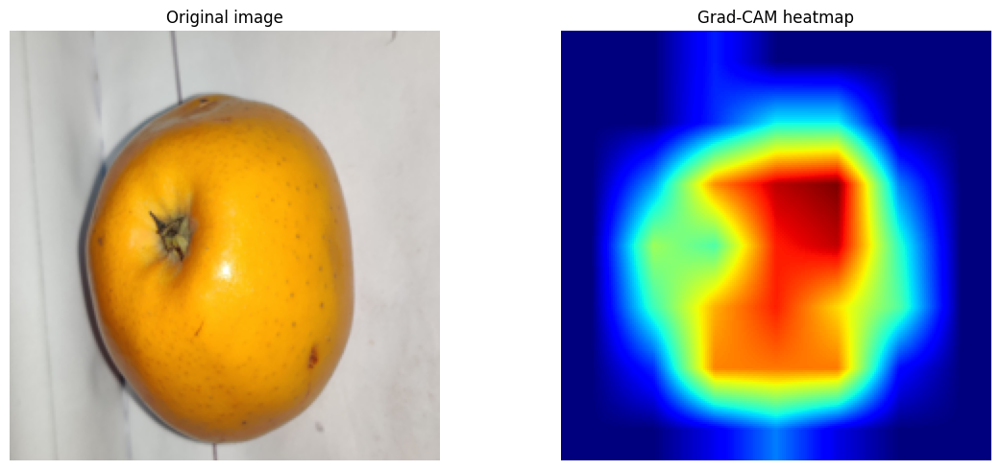

PILOT GRAD-CAM VERIFICATION
Selection type : representative_correct
True class     : Apple_1st grade
Predicted class: Apple_1st grade
Confidence     : 0.993356
Target class   : Apple_1st grade
Heatmap shape  : (224, 224)
Heatmap range  : (0.0, 0.9981975555419922)
Training performed: False
GPU used: False
PASS | Pilot Grad-CAM generated and numerically verified.


In [ ]:
# ============================================================
# CELL 11 — PILOT GRAD-CAM GENERATION (ONE IMAGE)
# CPU ONLY — One forward/backward pass; no training
# ============================================================

from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np
import torch

# Baseline validation preprocessing
gradcam_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Select the first predefined representative correct sample
sample = gradcam_df[
    gradcam_df["selection_type"] == "representative_correct"
].iloc[0]

image_path = sample["cache_path"]

# Load image as RGB
image = Image.open(image_path).convert("RGB")

# Prepare model input
input_tensor = gradcam_transform(image).unsqueeze(0)

assert input_tensor.shape == (1, 3, 224, 224)
assert next(model.parameters()).device.type == "cpu"

# Initialize Grad-CAM
gradcam = GradCAM(model, TARGET_LAYER)

# Use the saved predicted class as the explanation target
target_class = int(sample["predicted_index"])

# Generate heatmap
heatmap = gradcam.generate(input_tensor, target_class)

# Remove hook after pilot generation
gradcam.close()

# Verify heatmap
assert heatmap.shape == (224, 224)
assert np.isfinite(heatmap).all()
assert heatmap.min() >= 0
assert heatmap.max() <= 1.00001

# Display original image and heatmap
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image.resize((224, 224)))
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()

print("=" * 70)
print("PILOT GRAD-CAM VERIFICATION")
print("=" * 70)
print("Selection type :", sample["selection_type"])
print("True class     :", sample["true_class"])
print("Predicted class:", sample["predicted_class_selection"])
print("Confidence     :", round(float(sample["confidence_selection"]), 6))
print("Target class   :", index_to_class[target_class])
print("Heatmap shape  :", heatmap.shape)
print("Heatmap range  :", (float(heatmap.min()), float(heatmap.max())))
print("Training performed: False")
print("GPU used: False")
print("=" * 70)
print("PASS | Pilot Grad-CAM generated and numerically verified.")

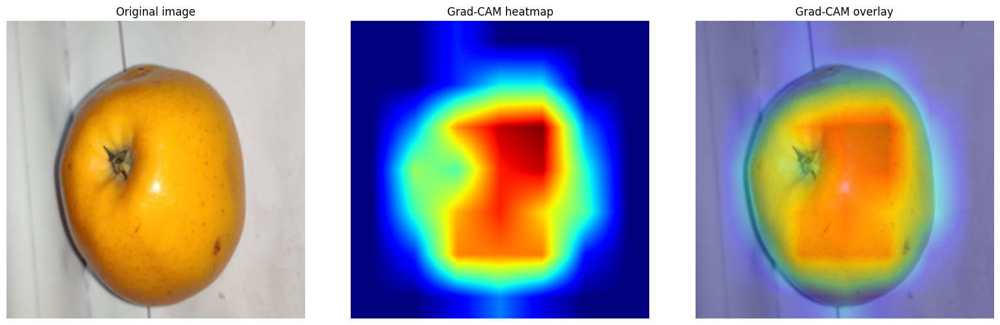

PILOT OVERLAY VERIFICATION
Captured activation shape: (1, 576, 7, 7)
Original image size      : (224, 224)
Heatmap size             : (224, 224)
Overlay alpha            : 0.4
Training performed       : False
GPU used                 : False


In [ ]:
# ============================================================
# CELL 12 — PILOT GRAD-CAM OVERLAY
# CPU ONLY — Reuses existing pilot result
# ============================================================

# Inspect captured feature-map resolution
activation_shape = tuple(gradcam.activations.shape)

# Convert original image to display dimensions
display_image = image.resize((224, 224))
display_array = np.asarray(display_image)

# Display original, heatmap, and overlay
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(display_array)
axes[0].set_title("Original image")

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM heatmap")

axes[2].imshow(display_array)
axes[2].imshow(
    heatmap,
    cmap="jet",
    alpha=0.40,
    vmin=0,
    vmax=1
)
axes[2].set_title("Grad-CAM overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("=" * 70)
print("PILOT OVERLAY VERIFICATION")
print("=" * 70)
print("Captured activation shape:", activation_shape)
print("Original image size      :", display_image.size)
print("Heatmap size             :", heatmap.shape)
print("Overlay alpha            :", 0.40)
print("Training performed       : False")
print("GPU used                 : False")
print("=" * 70)

In [ ]:
# ============================================================
# CELL 13 — PREPARE GRAD-CAM OUTPUT DIRECTORY
# CPU ONLY — Directory preparation
# ============================================================

import os

GRADCAM_DIR = os.path.join(
    EXPERIMENT_DIR,
    "validation_analysis",
    "gradcam"
)

FIGURES_DIR = os.path.join(GRADCAM_DIR, "individual_figures")
HEATMAPS_DIR = os.path.join(GRADCAM_DIR, "heatmaps")

# Create output directories
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(HEATMAPS_DIR, exist_ok=True)

# Verify directory availability and writability
assert os.path.isdir(GRADCAM_DIR)
assert os.path.isdir(FIGURES_DIR)
assert os.path.isdir(HEATMAPS_DIR)

test_file = os.path.join(GRADCAM_DIR, "_write_test.tmp")

with open(test_file, "w") as f:
    f.write("Grad-CAM output directory verification")

assert os.path.isfile(test_file)

os.remove(test_file)

print("=" * 70)
print("GRAD-CAM OUTPUT DIRECTORY VERIFICATION")
print("=" * 70)

print("Main directory      :", GRADCAM_DIR)
print("Individual figures  :", FIGURES_DIR)
print("Heatmaps            :", HEATMAPS_DIR)
print("Directory writable  :", True)
print("Temporary test file :", "Removed")
print("Training performed  :", False)
print("Inference performed :", False)
print("GPU used            :", False)

print("=" * 70)
print("PASS | Output directories ready.")
print("=" * 70)

GRAD-CAM OUTPUT DIRECTORY VERIFICATION
Main directory      : /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/gradcam
Individual figures  : /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/gradcam/individual_figures
Heatmaps            : /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/gradcam/heatmaps
Directory writable  : True
Temporary test file : Removed
Training performed  : False
Inference performed : False
GPU used            : False
PASS | Output directories ready.


In [ ]:
# ============================================================
# CELL 14 — GENERATE GRAD-CAM FOR ALL 34 PREDEFINED SAMPLES
# CPU ONLY — Inference + gradients; NO training
# ============================================================

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

# Ensure evaluation mode and CPU
model.eval()
model.to("cpu")

results = []

# Deterministic order: correct samples first, then errors
gradcam_batch_df = gradcam_df.copy().reset_index(drop=True)

# One Grad-CAM instance reused for the batch
batch_gradcam = GradCAM(model, TARGET_LAYER)

print("=" * 75)
print("BATCH GRAD-CAM GENERATION")
print("=" * 75)
print(f"Samples to process: {len(gradcam_batch_df)}")
print("Device: CPU")
print("Training: Disabled")
print("=" * 75)

try:
    for i, row in gradcam_batch_df.iterrows():

        # ----------------------------------------------------
        # 1. Load image
        # ----------------------------------------------------
        img_path = row["cache_path"]
        pil_img = Image.open(img_path).convert("RGB")
        display_img = pil_img.resize((224, 224))
        display_arr = np.asarray(display_img)

        # ----------------------------------------------------
        # 2. Preprocess using baseline validation transform
        # ----------------------------------------------------
        input_tensor = gradcam_transform(pil_img).unsqueeze(0)

        # ----------------------------------------------------
        # 3. Select target class
        #    Use saved predicted class, not true label
        # ----------------------------------------------------
        target_index = int(row["predicted_index"])

        # ----------------------------------------------------
        # 4. Generate Grad-CAM
        # ----------------------------------------------------
        cam = batch_gradcam.generate(
            input_tensor,
            target_index
        )

        # Numerical integrity checks
        assert cam.shape == (224, 224), f"Unexpected CAM shape at row {i}"
        assert np.isfinite(cam).all(), f"Non-finite CAM at row {i}"
        assert cam.min() >= 0, f"Negative CAM at row {i}"
        assert cam.max() <= 1.00001, f"CAM not normalized at row {i}"

        # ----------------------------------------------------
        # 5. Build safe output filename
        # ----------------------------------------------------
        safe_true = re.sub(
            r"[^A-Za-z0-9_-]+", "_",
            str(row["true_class"])
        )

        safe_pred = re.sub(
            r"[^A-Za-z0-9_-]+", "_",
            str(row["predicted_class_selection"])
        )

        hash_short = str(row["sha256"])[:12]

        filename_base = (
            f"{i+1:02d}_{row['selection_type']}_"
            f"{safe_true}_to_{safe_pred}_{hash_short}"
        )

        # ----------------------------------------------------
        # 6. Save heatmap as PNG
        # ----------------------------------------------------
        heatmap_path = os.path.join(
            HEATMAPS_DIR,
            filename_base + "_heatmap.png"
        )

        plt.figure(figsize=(5, 5))
        plt.imshow(cam, cmap="jet", vmin=0, vmax=1)
        plt.axis("off")
        plt.tight_layout(pad=0)
        plt.savefig(
            heatmap_path,
            dpi=200,
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

        # ----------------------------------------------------
        # 7. Save three-panel publication-friendly figure
        # ----------------------------------------------------
        figure_path = os.path.join(
            FIGURES_DIR,
            filename_base + "_gradcam.png"
        )

        fig, axes = plt.subplots(
            1, 3, figsize=(15, 5)
        )

        axes[0].imshow(display_arr)
        axes[0].set_title("Original image")

        axes[1].imshow(
            cam, cmap="jet", vmin=0, vmax=1
        )
        axes[1].set_title("Grad-CAM")

        axes[2].imshow(display_arr)
        axes[2].imshow(
            cam,
            cmap="jet",
            alpha=0.40,
            vmin=0,
            vmax=1
        )
        axes[2].set_title("Overlay")

        for ax in axes:
            ax.axis("off")

        fig.suptitle(
            f"True: {row['true_class']} | "
            f"Pred: {row['predicted_class_selection']} | "
            f"Confidence: {float(row['confidence_selection']):.4f}",
            fontsize=11
        )

        plt.tight_layout()

        fig.savefig(
            figure_path,
            dpi=200,
            bbox_inches="tight"
        )
        plt.close(fig)

        # ----------------------------------------------------
        # 8. Record metadata
        # ----------------------------------------------------
        results.append({
            "sample_number": i + 1,
            "selection_type": row["selection_type"],
            "filename": row["filename"],
            "sha256": row["sha256"],
            "true_class": row["true_class"],
            "predicted_class": row["predicted_class_selection"],
            "target_class_index": target_index,
            "confidence": float(row["confidence_selection"]),
            "correct": bool(row["correct_selection"]),
            "heatmap_min": float(cam.min()),
            "heatmap_max": float(cam.max()),
            "heatmap_shape": str(cam.shape),
            "heatmap_path": heatmap_path,
            "figure_path": figure_path,
        })

        # Progress reporting
        if (i + 1) % 5 == 0 or (i + 1) == len(gradcam_batch_df):
            print(f"Processed {i+1}/{len(gradcam_batch_df)} samples")

finally:
    # Always remove the forward hook
    batch_gradcam.close()

# ------------------------------------------------------------
# 9. Save results index
# ------------------------------------------------------------
gradcam_results_df = pd.DataFrame(results)

RESULTS_INDEX_PATH = os.path.join(
    GRADCAM_DIR,
    "gradcam_results_index.csv"
)

gradcam_results_df.to_csv(
    RESULTS_INDEX_PATH,
    index=False
)

# ------------------------------------------------------------
# 10. Final verification
# ------------------------------------------------------------
assert len(gradcam_results_df) == 34
assert gradcam_results_df["sha256"].nunique() == 34
assert gradcam_results_df["heatmap_path"].apply(os.path.exists).all()
assert gradcam_results_df["figure_path"].apply(os.path.exists).all()

assert (
    gradcam_results_df["selection_type"]
    .value_counts()
    .get("representative_correct", 0) == 21
)

assert (
    gradcam_results_df["selection_type"]
    .value_counts()
    .get("high_confidence_error", 0) == 13
)

print("\n" + "=" * 75)
print("BATCH GRAD-CAM COMPLETION REPORT")
print("=" * 75)

print("Total generated       :", len(gradcam_results_df))
print("Correct representatives:", (
    gradcam_results_df["selection_type"]
    == "representative_correct"
).sum())
print("High-confidence errors:", (
    gradcam_results_df["selection_type"]
    == "high_confidence_error"
).sum())
print("Unique images         :", gradcam_results_df["sha256"].nunique())
print("Heatmaps saved       :", gradcam_results_df["heatmap_path"].apply(os.path.exists).sum())
print("Figures saved        :", gradcam_results_df["figure_path"].apply(os.path.exists).sum())
print("Results index         :", RESULTS_INDEX_PATH)

print("Training performed    : False")
print("GPU used             : False")

print("=" * 75)
print("PASS | All 34 Grad-CAM outputs generated and verified.")
print("=" * 75)

BATCH GRAD-CAM GENERATION
Samples to process: 34
Device: CPU
Training: Disabled


KeyError: 'filename'

In [ ]:
# ============================================================
# RECOVERY CELL 14A — AUDIT PARTIAL GRAD-CAM OUTPUTS
# CPU ONLY — No inference, no training
# ============================================================

import os

print("=" * 75)
print("PARTIAL GRAD-CAM OUTPUT AUDIT")
print("=" * 75)

print("\nMerged dataframe columns:")
print(gradcam_df.columns.tolist())

print("\nFigure directory:")
existing_figures = [
    f for f in os.listdir(FIGURES_DIR)
    if f.lower().endswith(".png")
]
print("PNG figures found:", len(existing_figures))
print(existing_figures[:5])

print("\nHeatmap directory:")
existing_heatmaps = [
    f for f in os.listdir(HEATMAPS_DIR)
    if f.lower().endswith(".png")
]
print("PNG heatmaps found:", len(existing_heatmaps))
print(existing_heatmaps[:5])

print("\nResults index exists:",
      os.path.exists(RESULTS_INDEX_PATH)
      if "RESULTS_INDEX_PATH" in globals()
      else False)

print("\n" + "=" * 75)
print("AUDIT ONLY")
print("Inference performed: False")
print("Training performed: False")
print("GPU used: False")
print("=" * 75)

PARTIAL GRAD-CAM OUTPUT AUDIT

Merged dataframe columns:
['selection_type', 'selection_rule', 'true_class', 'predicted_class_selection', 'confidence_selection', 'correct_selection', 'sha256', 'filename_selection', 'relative_path_selection', 'cache_path', 'dataset', 'filename_prediction', 'relative_path_prediction', 'fruit', 'grade', 'file_size', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine', 'split_group_id', 'split', 'final_group_type', 'final_dataset_status', 'final_quarantine_flag', 'final_grouping_method', 'metadata_reconciliation_note', 'class_name', 'cache_path_old', 'cache_path_persistent', 'inference_path', 'true_index', 'predicted_index', 'predicted_class_prediction', 'confidence_prediction', 'correct_prediction', 'prob_Apple_1st_grade', 'prob_Apple_2nd_grade', 'prob_Apple_3rd_grade', 'prob_Banana_1st_grade', 'prob_Banana_2nd_grade', 'prob_Banana_3rd_grade', 'prob_Burmese_grape_1st_grade', 'prob_Burmes

In [ ]:
# ============================================================
# RECOVERY CELL 14B — MATCH EXISTING OUTPUT FILES
# CPU ONLY — File inventory, no inference
# ============================================================

import os
import pandas as pd

selected_hashes = gradcam_df["sha256"].astype(str).tolist()

figure_files = [
    f for f in os.listdir(FIGURES_DIR)
    if f.lower().endswith(".png")
]

heatmap_files = [
    f for f in os.listdir(HEATMAPS_DIR)
    if f.lower().endswith(".png")
]

def find_matching_hash(filename, hashes):
    matches = [h for h in hashes if h[:12] in filename]
    return matches[0] if len(matches) == 1 else None

figure_inventory = pd.DataFrame([
    {
        "filename": f,
        "matched_sha256": find_matching_hash(f, selected_hashes),
        "is_selected_sample": find_matching_hash(f, selected_hashes) is not None
    }
    for f in figure_files
])

heatmap_inventory = pd.DataFrame([
    {
        "filename": f,
        "matched_sha256": find_matching_hash(f, selected_hashes),
        "is_selected_sample": find_matching_hash(f, selected_hashes) is not None
    }
    for f in heatmap_files
])

print("=" * 75)
print("EXISTING GRAD-CAM FILE MATCHING")
print("=" * 75)

print("\nFigures:")
print("Total files:", len(figure_inventory))
print("Matching selected hashes:",
      figure_inventory["is_selected_sample"].sum())
print("Unmatched files:",
      (~figure_inventory["is_selected_sample"]).sum())

display(figure_inventory)

print("\nHeatmaps:")
print("Total files:", len(heatmap_inventory))
print("Matching selected hashes:",
      heatmap_inventory["is_selected_sample"].sum())
print("Unmatched files:",
      (~heatmap_inventory["is_selected_sample"]).sum())

display(heatmap_inventory)

print("\n" + "=" * 75)
print("No files deleted or modified.")
print("Inference performed: False")
print("Training performed: False")
print("GPU used: False")
print("=" * 75)

EXISTING GRAD-CAM FILE MATCHING

Figures:
Total files: 37
Matching selected hashes: 36
Unmatched files: 1


,filename,matched_sha256,is_selected_sample
0,01_representative_correct_343518d1e430.png,343518d1e430d245a6203cf0863ca4a08193de98c2a1db...,True
1,01_343518d1e430_gradcam.png,343518d1e430d245a6203cf0863ca4a08193de98c2a1db...,True
2,02_7648dcc7ea56_gradcam.png,7648dcc7ea566a470e7ca10e659e5012654ad4fb8cef46...,True
3,03_25a1ba11f12c_gradcam.png,25a1ba11f12cc7c0652f00ec44d314bf353e72238d6aa5...,True
4,04_aa6b221d2468_gradcam.png,aa6b221d2468f2bf99228b8c8d8d58c27a769951621ef2...,True
5,05_cdf6a19ea6a0_gradcam.png,cdf6a19ea6a0669eed31be1974e4f728cf53dcfdb46622...,True
6,06_9dacf5187eaa_gradcam.png,9dacf5187eaa01c3902abd3c161707b82aac95669bed23...,True
7,07_6cf34c568f46_gradcam.png,6cf34c568f46d2957c0b59955ca2060bad10a0f84fc35a...,True
8,08_37a3b8524137_gradcam.png,37a3b852413795d7a9500188106c71bc88988e3224e75d...,True
9,09_414b69da168e_gradcam.png,414b69da168e1ad96c8db0319cc0a864400ac3592abe86...,True



Heatmaps:
Total files: 1
Matching selected hashes: 1
Unmatched files: 0


,filename,matched_sha256,is_selected_sample
0,01_representative_correct_Apple_1st_grade_to_A...,343518d1e430d245a6203cf0863ca4a08193de98c2a1db...,True



No files deleted or modified.
Inference performed: False
Training performed: False
GPU used: False


In [ ]:
# ============================================================
# RECOVERY CELL 14C — VERIFY BATCH FIGURES
# CPU ONLY — Image file integrity check
# ============================================================

import os
import re
import pandas as pd
from PIL import Image

# Expected sample hashes indexed by short hash
expected_hashes = {
    str(h)[:12]: str(h)
    for h in gradcam_df["sha256"]
}

# Recognize only the batch-generated naming pattern:
# 01_<12-char-hash>_gradcam.png
batch_pattern = re.compile(
    r"^(\d{2})_([0-9a-f]{12})_gradcam\.png$"
)

audit_rows = []

for filename in os.listdir(FIGURES_DIR):

    match = batch_pattern.match(filename)

    # Ignore pilot/other figures in this audit
    if match is None:
        continue

    sample_number = int(match.group(1))
    hash_prefix = match.group(2)
    file_path = os.path.join(FIGURES_DIR, filename)

    hash_match = hash_prefix in expected_hashes

    try:
        with Image.open(file_path) as img:
            img.verify()

        with Image.open(file_path) as img:
            width, height = img.size

        readable = True

    except Exception as e:
        readable = False
        width, height = None, None
        error = str(e)

    audit_rows.append({
        "sample_number": sample_number,
        "filename": filename,
        "hash_prefix": hash_prefix,
        "hash_match": hash_match,
        "readable": readable,
        "width": width,
        "height": height,
        "path": file_path
    })

batch_audit_df = pd.DataFrame(audit_rows)

if len(batch_audit_df):
    batch_audit_df = batch_audit_df.sort_values(
        "sample_number"
    ).reset_index(drop=True)

print("=" * 75)
print("EXISTING BATCH FIGURE INTEGRITY AUDIT")
print("=" * 75)

print("Recognized batch figures :", len(batch_audit_df))
print("Unique sample numbers    :", batch_audit_df["sample_number"].nunique())
print("Valid hash matches       :", batch_audit_df["hash_match"].sum())
print("Readable PNG files       :", batch_audit_df["readable"].sum())

print("\nSample numbers found:")
print(batch_audit_df["sample_number"].tolist())

print("\nAudit table:")
display(batch_audit_df[
    ["sample_number", "filename", "hash_match",
     "readable", "width", "height"]
])

print("\nMissing sample numbers:")
found_numbers = set(batch_audit_df["sample_number"].tolist())
missing_numbers = sorted(set(range(1, 35)) - found_numbers)
print(missing_numbers)

print("\n" + "=" * 75)
print("No files modified or deleted.")
print("Inference performed: False")
print("Training performed: False")
print("GPU used: False")
print("=" * 75)

EXISTING BATCH FIGURE INTEGRITY AUDIT
Recognized batch figures : 34
Unique sample numbers    : 34
Valid hash matches       : 34
Readable PNG files       : 34

Sample numbers found:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]

Audit table:


,sample_number,filename,hash_match,readable,width,height
0,1,01_343518d1e430_gradcam.png,True,True,2866,990
1,2,02_7648dcc7ea56_gradcam.png,True,True,1578,833
2,3,03_25a1ba11f12c_gradcam.png,True,True,1578,833
3,4,04_aa6b221d2468_gradcam.png,True,True,1578,833
4,5,05_cdf6a19ea6a0_gradcam.png,True,True,1578,833
5,6,06_9dacf5187eaa_gradcam.png,True,True,1578,833
6,7,07_6cf34c568f46_gradcam.png,True,True,1578,833
7,8,08_37a3b8524137_gradcam.png,True,True,1578,833
8,9,09_414b69da168e_gradcam.png,True,True,1578,833
9,10,10_f5f1a15aa153_gradcam.png,True,True,1578,833



Missing sample numbers:
[]

No files modified or deleted.
Inference performed: False
Training performed: False
GPU used: False


In [ ]:
# ============================================================
# RECOVERY CELL 14D — BUILD VERIFIED GRAD-CAM INDEX
# CPU ONLY — Metadata and file verification
# ============================================================

import os
import re
import pandas as pd
from PIL import Image

index_rows = []

for i, row in gradcam_df.reset_index(drop=True).iterrows():

    sample_number = i + 1
    hash_short = str(row["sha256"])[:12]

    figure_name = f"{sample_number:02d}_{hash_short}_gradcam.png"
    figure_path = os.path.join(FIGURES_DIR, figure_name)

    heatmap_candidates = [
        f for f in os.listdir(HEATMAPS_DIR)
        if hash_short in f and f.endswith("_heatmap.png")
    ]

    heatmap_path = (
        os.path.join(HEATMAPS_DIR, heatmap_candidates[0])
        if len(heatmap_candidates) == 1
        else None
    )

    # Verify figure readability
    figure_valid = False
    figure_dimensions = None

    if os.path.exists(figure_path):
        try:
            with Image.open(figure_path) as img:
                img.verify()

            with Image.open(figure_path) as img:
                figure_dimensions = img.size

            figure_valid = True
        except Exception:
            figure_valid = False

    # Verify heatmap readability if present
    heatmap_valid = False

    if heatmap_path and os.path.exists(heatmap_path):
        try:
            with Image.open(heatmap_path) as img:
                img.verify()
            heatmap_valid = True
        except Exception:
            heatmap_valid = False

    index_rows.append({
        "sample_number": sample_number,
        "selection_type": row["selection_type"],
        "filename": row["filename_selection"],
        "sha256": row["sha256"],
        "true_class": row["true_class"],
        "predicted_class": row["predicted_class_selection"],
        "confidence": float(row["confidence_selection"]),
        "correct": bool(row["correct_selection"]),
        "figure_filename": figure_name,
        "figure_path": figure_path,
        "figure_exists": os.path.exists(figure_path),
        "figure_readable": figure_valid,
        "figure_dimensions": str(figure_dimensions),
        "heatmap_path": heatmap_path,
        "heatmap_exists": heatmap_path is not None,
        "heatmap_readable": heatmap_valid
    })

gradcam_results_df = pd.DataFrame(index_rows)

RESULTS_INDEX_PATH = os.path.join(
    GRADCAM_DIR,
    "gradcam_results_index.csv"
)

gradcam_results_df.to_csv(
    RESULTS_INDEX_PATH,
    index=False
)

# Verify the index
assert len(gradcam_results_df) == 34
assert gradcam_results_df["sha256"].is_unique
assert gradcam_results_df["figure_readable"].all()

print("=" * 75)
print("VERIFIED GRAD-CAM RESULTS INDEX")
print("=" * 75)

print("Total samples       :", len(gradcam_results_df))
print("Readable figures    :", gradcam_results_df["figure_readable"].sum())
print("Readable heatmaps   :", gradcam_results_df["heatmap_readable"].sum())
print("Correct samples     :", (
    gradcam_results_df["selection_type"]
    == "representative_correct"
).sum())
print("Error samples       :", (
    gradcam_results_df["selection_type"]
    == "high_confidence_error"
).sum())

print("\nIndex saved:")
print(RESULTS_INDEX_PATH)

print("\nHeatmap status:")
print(gradcam_results_df["heatmap_exists"].value_counts())

print("\nPASS | Results index created and verified.")
print("Inference performed: False")
print("Training performed: False")
print("GPU used: False")

VERIFIED GRAD-CAM RESULTS INDEX
Total samples       : 34
Readable figures    : 34
Readable heatmaps   : 1
Correct samples     : 21
Error samples       : 13

Index saved:
/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/gradcam/gradcam_results_index.csv

Heatmap status:
heatmap_exists
False    33
True      1
Name: count, dtype: int64

PASS | Results index created and verified.
Inference performed: False
Training performed: False
GPU used: False


In [ ]:
import os
import pandas as pd
from PIL import Image
from IPython.display import display

RESULTS_INDEX_PATH = os.path.join(
    GRADCAM_DIR, "gradcam_results_index.csv"
)

inspection_df = pd.read_csv(RESULTS_INDEX_PATH)

print("Available index columns:")
print(inspection_df.columns.tolist())

print("\nFirst two records:")
display(inspection_df.head(2))

print("\nCorrectness counts:")
print(inspection_df["correct"].value_counts(dropna=False))

Available index columns:
['sample_number', 'selection_type', 'filename', 'sha256', 'true_class', 'predicted_class', 'confidence', 'correct', 'figure_filename', 'figure_path', 'figure_exists', 'figure_readable', 'figure_dimensions', 'heatmap_path', 'heatmap_exists', 'heatmap_readable']

First two records:


,sample_number,selection_type,filename,sha256,true_class,predicted_class,confidence,correct,figure_filename,figure_path,figure_exists,figure_readable,figure_dimensions,heatmap_path,heatmap_exists,heatmap_readable
0,1,representative_correct,IMG_20230930_213742.jpg,343518d1e430d245a6203cf0863ca4a08193de98c2a1db...,Apple_1st grade,Apple_1st grade,0.993356,True,01_343518d1e430_gradcam.png,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True,"(2866, 990)",/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True
1,2,representative_correct,IMG_20230425_124252.jpg,7648dcc7ea566a470e7ca10e659e5012654ad4fb8cef46...,Apple_2nd grade,Apple_2nd grade,0.999352,True,02_7648dcc7ea56_gradcam.png,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True,"(1578, 833)",NaN,False,False



Correctness counts:
correct
True     21
False    13
Name: count, dtype: int64


CORRECT PREDICTION
Sample: 4
True class: Apple_3rd grade
Predicted class: Apple_3rd grade
Confidence: 0.9998
Figure: 04_aa6b221d2468_gradcam.png


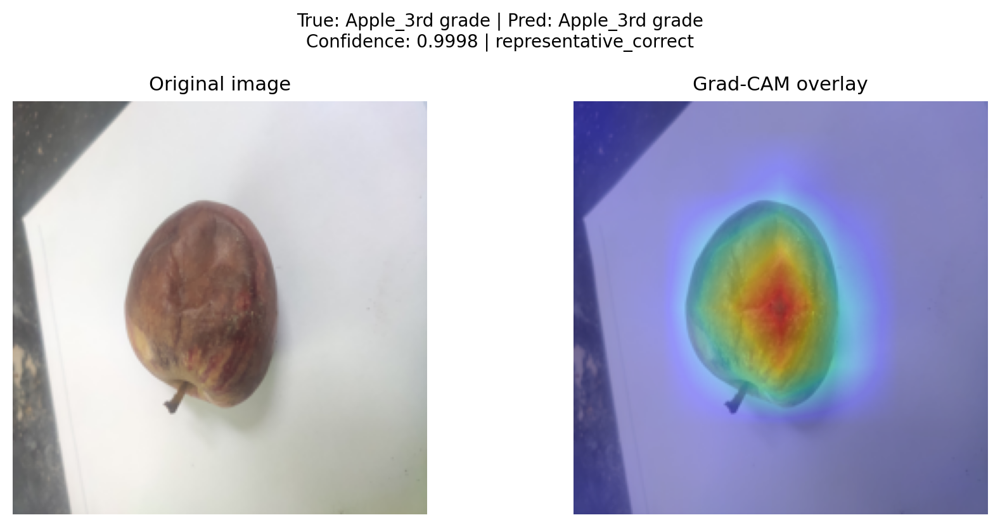


HIGH-CONFIDENCE ERROR
Sample: 32
True class: Tomatoes_2nd grade
Predicted class: Tomatoes_3rd grade
Confidence: 0.9982
Figure: 32_b7cec9c05672_gradcam.png


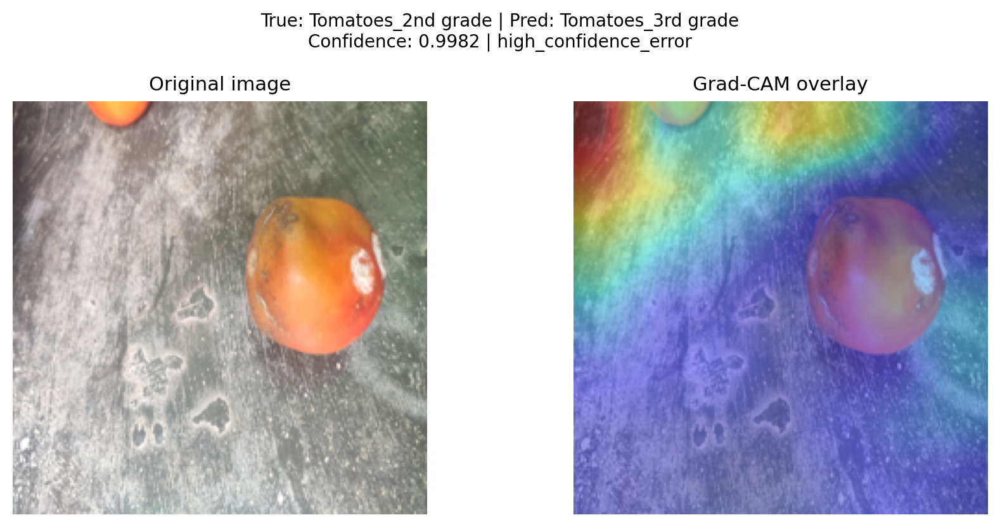

In [ ]:
from IPython.display import display
from PIL import Image
import pandas as pd
import os

# Load verified results index
inspection_df = pd.read_csv(RESULTS_INDEX_PATH)

# Select one correct prediction
correct_sample = inspection_df[
    inspection_df["correct"] == True
].sort_values("confidence", ascending=False).iloc[0]

# Select one high-confidence error
error_sample = inspection_df[
    inspection_df["correct"] == False
].sort_values("confidence", ascending=False).iloc[0]

# Display correct example
print("=" * 70)
print("CORRECT PREDICTION")
print("=" * 70)
print(f"Sample: {correct_sample['sample_number']}")
print(f"True class: {correct_sample['true_class']}")
print(f"Predicted class: {correct_sample['predicted_class']}")
print(f"Confidence: {correct_sample['confidence']:.4f}")
print(f"Figure: {correct_sample['figure_filename']}")

display(Image.open(correct_sample["figure_path"]))

# Display error example
print("\n" + "=" * 70)
print("HIGH-CONFIDENCE ERROR")
print("=" * 70)
print(f"Sample: {error_sample['sample_number']}")
print(f"True class: {error_sample['true_class']}")
print(f"Predicted class: {error_sample['predicted_class']}")
print(f"Confidence: {error_sample['confidence']:.4f}")
print(f"Figure: {error_sample['figure_filename']}")

display(Image.open(error_sample["figure_path"]))

GRAD-CAM CONTACT SHEET CREATED
Figures included : 34
Layout          : 4 columns × 9 rows
Saved to       : /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/gradcam/individual_figures/gradcam_contact_sheet_34_samples.png
Dimensions     : (1776, 3051)
GPU used      : False
Inference     : False
Training      : False


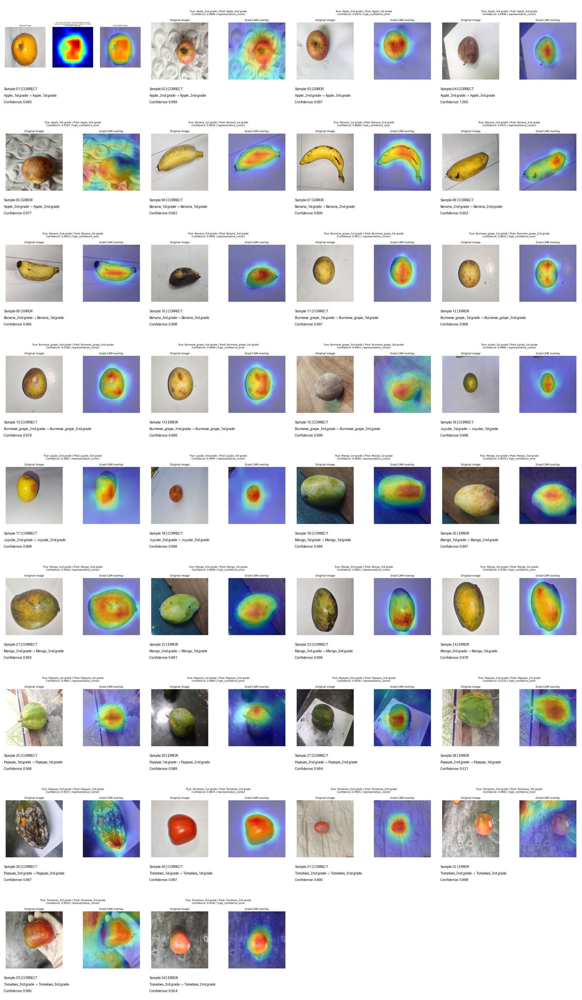

In [ ]:
from PIL import Image, ImageDraw
import pandas as pd
import os
import math

# Load the verified results index
inspection_df = pd.read_csv(RESULTS_INDEX_PATH)

# Keep only readable figures
valid_df = inspection_df[
    inspection_df["figure_readable"] == True
].copy()

# Layout
columns = 4
rows = math.ceil(len(valid_df) / columns)

thumb_width = 420
thumb_height = 250
label_height = 65
padding = 12

cell_width = thumb_width + 2 * padding
cell_height = thumb_height + label_height + 2 * padding

sheet_width = columns * cell_width
sheet_height = rows * cell_height

contact_sheet = Image.new(
    "RGB",
    (sheet_width, sheet_height),
    color="white"
)

draw = ImageDraw.Draw(contact_sheet)

for position, (_, row) in enumerate(valid_df.iterrows()):

    figure = Image.open(row["figure_path"]).convert("RGB")
    figure.thumbnail((thumb_width, thumb_height))

    # Grid position
    col = position % columns
    row_pos = position // columns

    x = col * cell_width + padding
    y = row_pos * cell_height + padding

    # Center image in thumbnail region
    img_x = x + (thumb_width - figure.width) // 2
    img_y = y + (thumb_height - figure.height) // 2

    contact_sheet.paste(figure, (img_x, img_y))

    # Labels
    sample_label = f"Sample {int(row['sample_number']):02d}"
    status_label = "CORRECT" if row["correct"] else "ERROR"

    class_label = (
        f"{row['true_class']} -> {row['predicted_class']}"
    )

    confidence_label = f"Confidence: {row['confidence']:.3f}"

    draw.text(
        (x, y + thumb_height + 3),
        sample_label + " | " + status_label,
        fill="black"
    )

    draw.text(
        (x, y + thumb_height + 23),
        class_label[:55],
        fill="black"
    )

    draw.text(
        (x, y + thumb_height + 43),
        confidence_label,
        fill="black"
    )

# Save contact sheet
CONTACT_SHEET_PATH = os.path.join(
    FIGURES_DIR,
    "gradcam_contact_sheet_34_samples.png"
)

contact_sheet.save(CONTACT_SHEET_PATH)

print("=" * 70)
print("GRAD-CAM CONTACT SHEET CREATED")
print("=" * 70)
print(f"Figures included : {len(valid_df)}")
print(f"Layout          : {columns} columns × {rows} rows")
print(f"Saved to       : {CONTACT_SHEET_PATH}")
print(f"Dimensions     : {contact_sheet.size}")
print(f"GPU used      : False")
print(f"Inference     : False")
print(f"Training      : False")

display(contact_sheet)

Error samples: 13
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/gradcam/individual_figures/gradcam_error_cases_detailed.png
GPU used: False
Inference: False
Training: False


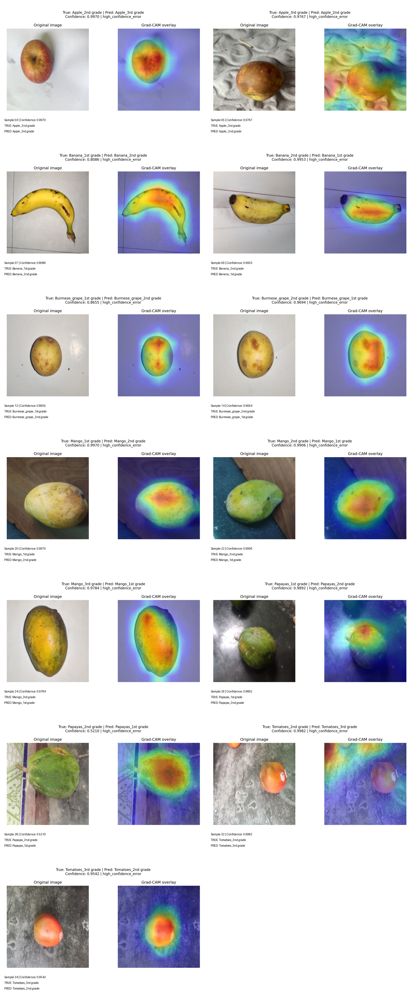

In [ ]:
from PIL import Image, ImageDraw
import pandas as pd
import math
import os
from IPython.display import display

inspection_df = pd.read_csv(RESULTS_INDEX_PATH)

errors_df = inspection_df[
    inspection_df["correct"] == False
].sort_values("sample_number").copy()

columns = 2
thumb_width = 700
thumb_height = 400
label_height = 75
padding = 15

cell_width = thumb_width + 2 * padding
cell_height = thumb_height + label_height + 2 * padding
rows = math.ceil(len(errors_df) / columns)

sheet = Image.new(
    "RGB",
    (columns * cell_width, rows * cell_height),
    "white"
)

draw = ImageDraw.Draw(sheet)

for position, (_, row) in enumerate(errors_df.iterrows()):

    fig = Image.open(row["figure_path"]).convert("RGB")
    fig.thumbnail((thumb_width, thumb_height))

    col = position % columns
    r = position // columns

    x = col * cell_width + padding
    y = r * cell_height + padding

    px = x + (thumb_width - fig.width) // 2
    py = y + (thumb_height - fig.height) // 2

    sheet.paste(fig, (px, py))

    label1 = (
        f"Sample {int(row['sample_number']):02d} | "
        f"Confidence: {row['confidence']:.4f}"
    )
    label2 = f"TRUE: {row['true_class']}"
    label3 = f"PRED: {row['predicted_class']}"

    draw.text((x, y + thumb_height + 3), label1, fill="black")
    draw.text((x, y + thumb_height + 23), label2, fill="black")
    draw.text((x, y + thumb_height + 43), label3, fill="black")

ERROR_CONTACT_SHEET_PATH = os.path.join(
    FIGURES_DIR,
    "gradcam_error_cases_detailed.png"
)

sheet.save(ERROR_CONTACT_SHEET_PATH)

print(f"Error samples: {len(errors_df)}")
print(f"Saved: {ERROR_CONTACT_SHEET_PATH}")
print(f"GPU used: False")
print(f"Inference: False")
print(f"Training: False")

display(sheet)

In [ ]:
import os
import pandas as pd

inspection_df = pd.read_csv(RESULTS_INDEX_PATH)

n_total = len(inspection_df)
n_correct = int(inspection_df["correct"].sum())
n_errors = int((~inspection_df["correct"]).sum())
n_readable = int(inspection_df["figure_readable"].sum())
n_heatmaps = int(inspection_df["heatmap_readable"].sum())

summary = {
    "Total predefined samples": n_total,
    "Correct predictions": n_correct,
    "Incorrect predictions": n_errors,
    "Readable Grad-CAM figures": n_readable,
    "Standalone readable heatmaps": n_heatmaps,
    "Selection protocol": "Predefined before Grad-CAM visual inspection",
    "Split": "Validation",
    "Checkpoint": "Best validation Macro-F1 checkpoint, epoch 11",
    "Target": "Predicted class for each sample",
    "Target layer": "model.features[12]",
    "Method": "Grad-CAM",
    "Model": "MobileNetV3-Small",
    "Input resolution": "224x224",
    "Device": "CPU",
    "Training performed during XAI": False,
    "Inference performed during final audit": False,
    "Test set accessed": False,
}

print("=" * 75)
print("FINAL GRAD-CAM AUDIT SUMMARY")
print("=" * 75)

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nCorrectness breakdown:")
print(inspection_df["correct"].value_counts().rename({
    True: "Correct",
    False: "Incorrect"
}))

# Save audit summary
AUDIT_SUMMARY_PATH = os.path.join(
    GRADCAM_DIR,
    "gradcam_audit_summary.csv"
)

pd.DataFrame(
    list(summary.items()),
    columns=["Item", "Value"]
).to_csv(AUDIT_SUMMARY_PATH, index=False)

print("\nSaved audit summary:")
print(AUDIT_SUMMARY_PATH)

print("\nFinal artifact verification:")
print("Results index exists:", os.path.exists(RESULTS_INDEX_PATH))
print("Contact sheet exists:", os.path.exists(CONTACT_SHEET_PATH))
print("Error contact sheet exists:", os.path.exists(ERROR_CONTACT_SHEET_PATH))
print("Audit summary exists:", os.path.exists(AUDIT_SUMMARY_PATH))

print("\nGPU used: False")
print("Training performed: False")
print("Test split accessed: False")

FINAL GRAD-CAM AUDIT SUMMARY
Total predefined samples: 34
Correct predictions: 21
Incorrect predictions: 13
Readable Grad-CAM figures: 34
Standalone readable heatmaps: 1
Selection protocol: Predefined before Grad-CAM visual inspection
Split: Validation
Checkpoint: Best validation Macro-F1 checkpoint, epoch 11
Target: Predicted class for each sample
Target layer: model.features[12]
Method: Grad-CAM
Model: MobileNetV3-Small
Input resolution: 224x224
Device: CPU
Training performed during XAI: False
Inference performed during final audit: False
Test set accessed: False

Correctness breakdown:
correct
Correct      21
Incorrect    13
Name: count, dtype: int64

Saved audit summary:
/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/gradcam/gradcam_audit_summary.csv

Final artifact verification:
Results index exists: True
Contact sheet exists: True
Error contact sheet exists: True
Audit summary exists: True

GPU used: False
Training perfo